# Healthcare Admissions: Exploratory Data Analysis



In [0]:
# Import the libraries used in this notebook.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Show all columns when a table is displayed.
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

## 1. Data Overview

**Data Ingestion**

In [0]:
# Load the dataset. The CSV file must be in the same folder as this notebook.
df = pd.read_csv("/Workspace/Users/molatlhegipolitemasego@gmail.com/Healthcare EDA Assignment/1780593902717_healthcare_dataset.csv")
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


Data Inspection

### Q1. Number of rows and columns

In [0]:
# Display the number of rows and columns.
print(df.shape)

(55500, 15)


**Observation**

The dataset has 55,500 rows (admissions) and 15 columns.

### Q2. Available columns

In [0]:
# List the names of all columns.
list(df.columns)

['Name',
 'Age',
 'Gender',
 'Blood Type',
 'Medical Condition',
 'Date of Admission',
 'Doctor',
 'Hospital',
 'Insurance Provider',
 'Billing Amount',
 'Room Number',
 'Admission Type',
 'Discharge Date',
 'Medication',
 'Test Results']

### Q3. Data types, sample values and summary statistics

In [0]:
# Show data types and non-null counts, then a random sample of rows and summary statistics.
df.dtypes
df.info()
display(df.sample(5, random_state=1))
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55500 entries, 0 to 55499
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                55500 non-null  object 
 1   Age                 55500 non-null  int64  
 2   Gender              55500 non-null  object 
 3   Blood Type          55500 non-null  object 
 4   Medical Condition   55500 non-null  object 
 5   Date of Admission   55500 non-null  object 
 6   Doctor              55500 non-null  object 
 7   Hospital            55500 non-null  object 
 8   Insurance Provider  55500 non-null  object 
 9   Billing Amount      55500 non-null  float64
 10  Room Number         55500 non-null  int64  
 11  Admission Type      55500 non-null  object 
 12  Discharge Date      55500 non-null  object 
 13  Medication          55500 non-null  object 
 14  Test Results        55500 non-null  object 
dtypes: float64(1), int64(2), object(12)
memory usage: 6.4

Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
MichAel MILLs,63,Male,O-,Cancer,2023-06-30,Ronald Gordon,Weber-Mcpherson,Medicare,47417.999803570194,387,Elective,2023-07-06,Paracetamol,Inconclusive
wiLlIam RAmirEz,81,Female,B-,Asthma,2022-09-17,Christian Galvan,Murphy-French,Aetna,10003.05467294819,249,Emergency,2022-10-14,Ibuprofen,Normal
JosEph MeYER,51,Male,AB-,Arthritis,2024-01-07,Daniel Fuller,Cannon-Dorsey,Cigna,37291.17053994772,149,Emergency,2024-01-27,Aspirin,Inconclusive
DR. micHaEl MckAy,64,Male,O+,Cancer,2019-05-31,Dawn Navarro,"Mcconnell and Rios, Clark",UnitedHealthcare,-199.66379451099877,122,Urgent,2019-06-12,Ibuprofen,Abnormal
MoNiCA CaRpEnTER,72,Male,O+,Diabetes,2021-12-12,Douglas Walters,Sons and Lloyd,Aetna,41148.67810268024,470,Elective,2022-01-05,Paracetamol,Inconclusive


Age,Billing Amount,Room Number
55500.0,55500.0,55500.0
51.53945945945946,25539.316097211795,301.1348288288288
19.602453808514348,14211.454430864413,115.2430687009733
13.0,-2008.4921398591305,101.0
35.0,13241.224652365136,202.0
52.0,25538.069375965664,302.0
68.0,37820.508435784795,401.0
89.0,52764.276736469175,500.0


**Observation**

Most columns are text. Age, Billing Amount and Room Number are numeric. Both date columns are stored as text, so they must be converted before use. Age runs from 13 to 89. The minimum Billing Amount is negative, which is not valid. The sample shows patient names with random capital letters.

## 2. Data Dictionary

| Column | Data type | What it means | Example value |
|---|---|---|---|
| Name | Text | Full name of the patient, sometimes with a title (Mr., Dr.) or suffix (MD, Jr.) | Bobby JacksOn |
| Age | Whole number | Age of the patient in years at admission | 30 |
| Gender | Text | Gender of the patient (Male or Female) | Male |
| Blood Type | Text | Blood group of the patient (eight types) | B- |
| Medical Condition | Text | Main condition the patient was admitted for | Cancer |
| Date of Admission | Text (date) | Day the patient was admitted | 2024-01-31 |
| Doctor | Text | Doctor responsible for the patient | Matthew Smith |
| Hospital | Text | Hospital that treated the patient | Sons and Miller |
| Insurance Provider | Text | Company that covers the patient's costs | Blue Cross |
| Billing Amount | Decimal number | Cost of the admission (currency not stated) | 18856.28 |
| Room Number | Whole number | Room the patient stayed in (101 to 500) | 328 |
| Admission Type | Text | How the patient arrived: Emergency, Urgent or Elective (planned) | Urgent |
| Discharge Date | Text (date) | Day the patient left hospital | 2024-02-02 |
| Medication | Text | Main medicine given during the stay | Paracetamol |
| Test Results | Text | Outcome of the tests: Normal, Abnormal or Inconclusive | Normal |

## 3. Data-Quality Checks

### Q4. Missing values

In [0]:
# Count missing values in each column.
print(df.isnull().sum())

# Blank text such as "" or "   " would not be counted as missing, so check for it too.
blank_entries = sum((df[col].astype(str).str.strip() == "").sum() for col in df.columns)
print("Blank text entries:", blank_entries)

Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
dtype: int64
Blank text entries: 0


**Observation**

No column has missing values and there are no blank entries. Nothing needs to be filled in or removed for missing data.

### Q5. Duplicate rows

In [0]:
# Count rows that are exact copies of another row, then look at a few examples.
duplicate_count = df.duplicated().sum()
print("Duplicate rows:", duplicate_count)
print("Share of all rows (%):", round(duplicate_count / len(df) * 100, 2))
display(df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(6))

Duplicate rows: 534
Share of all rows (%): 0.96


Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
ABIgaIL YOung,41,Female,O+,Hypertension,2022-12-15,Edward Kramer,Moore-Mcdaniel,UnitedHealthcare,1983.5682967188225,192,Elective,2023-01-13,Ibuprofen,Normal
ABIgaIL YOung,41,Female,O+,Hypertension,2022-12-15,Edward Kramer,Moore-Mcdaniel,UnitedHealthcare,1983.5682967188225,192,Elective,2023-01-13,Ibuprofen,Normal
ALIcia taYLoR,78,Male,O+,Asthma,2022-09-18,Dawn Burton,Wright LLC,Aetna,31465.274979005477,149,Elective,2022-10-15,Aspirin,Inconclusive
ALIcia taYLoR,78,Male,O+,Asthma,2022-09-18,Dawn Burton,Wright LLC,Aetna,31465.274979005477,149,Elective,2022-10-15,Aspirin,Inconclusive
AMy GREEN,79,Female,B+,Obesity,2021-03-30,Brett Johnson,Taylor-Williamson,UnitedHealthcare,23402.35849072853,249,Elective,2021-04-27,Penicillin,Abnormal
AMy GREEN,79,Female,B+,Obesity,2021-03-30,Brett Johnson,Taylor-Williamson,UnitedHealthcare,23402.35849072853,249,Elective,2021-04-27,Penicillin,Abnormal


**Observation**

534 rows (0.96%) are exact copies. Left in, they would count some admissions twice.

### Q6. Unusual values and text consistency

In [0]:
# Check the range of the numeric columns and count negative bills.
print("Age:", df["Age"].min(), "to", df["Age"].max())
print("Room Number:", df["Room Number"].min(), "to", df["Room Number"].max())
print("Billing Amount:", round(df["Billing Amount"].min(), 2), "to", round(df["Billing Amount"].max(), 2))
negative_bills = (df["Billing Amount"] < 0).sum()
print("Negative bills:", negative_bills, "(", round(negative_bills / len(df) * 100, 2), "% of rows )")

# A discharge before admission would also be impossible, so check the dates.
admit = pd.to_datetime(df["Date of Admission"])
discharge = pd.to_datetime(df["Discharge Date"])
print("Discharges before admission:", (discharge < admit).sum())
print("Admission dates run from", admit.min().date(), "to", admit.max().date())

Age: 13 to 89
Room Number: 101 to 500
Billing Amount: -2008.49 to 52764.28
Negative bills: 108 ( 0.19 % of rows )
Discharges before admission: 0
Admission dates run from 2019-05-08 to 2024-05-07


**Observation**

Age and Room Number are in plausible ranges. 108 bills are negative (0.19% of rows). A bill cannot be negative, so these are likely errors or refunds. They would pull billing averages down. Every discharge is after its admission. The data covers May 2019 to May 2024, so 2019 and 2024 are part-years.

In [0]:
# Check how consistently names and hospital names are written.
print(df["Name"].head(5).tolist())
print("Names not in proper case:", (df["Name"] != df["Name"].str.title()).sum())
print("Names with a title or suffix:",
      df["Name"].str.contains(r"^(?:mr|mrs|ms|dr)\.|\s(?:md|dds|dvm|phd|jr\.|ii|iii)$", case=False, regex=True).sum())
print("Hospital names ending in a comma:", df["Hospital"].str.endswith(",").sum())

['Bobby JacksOn', 'LesLie TErRy', 'DaNnY sMitH', 'andrEw waTtS', 'adrIENNE bEll']
Names not in proper case: 55467
Names with a title or suffix: 2082
Hospital names ending in a comma: 4776


**Observation**

Almost every name has random capital letters, and some include a title or suffix. 4,776 hospital names end in a stray comma, which could make one hospital look like two.

**Data-quality summary**

1. Missing values: none.
2. Duplicate rows: 534 (0.96%). Minor, but they double count admissions and must be removed.
3. Negative bills: 108 (0.19%). Minor in size, but they distort billing averages.
4. Patient names: inconsistent capital letters. Cosmetic and easy to fix.
5. Hospital names: stray trailing commas. Cosmetic and easy to fix.
6. Dates: stored as text. Easy to fix, and no discharge is before its admission.

## 4. Data Cleaning

In [0]:
# Work on a copy so the original data stays unchanged.
df_clean = df.copy()

### 4.1 Standardise text

In [0]:
# Remove extra spaces and put patient names in proper case, e.g. "pOLIte aLf" becomes "Polite Alf".
# This is done before the duplicate check so rows that differ only in capital letters are compared fairly.
df_clean["Name"] = df_clean["Name"].str.strip()
df_clean["Name"] = df_clean["Name"].str.replace(r"\s+", " ", regex=True)
df_clean["Name"] = df_clean["Name"].str.title()

# Proper case turns suffixes such as MD into "Md", so put them back.
suffix_fixes = {r"\bMd$": "MD", r"\bDds$": "DDS", r"\bDvm$": "DVM", r"\bPhd$": "PhD", r"\bIii$": "III", r"\bIi$": "II"}
for wrong, right in suffix_fixes.items():
    df_clean["Name"] = df_clean["Name"].str.replace(wrong, right, regex=True)

# Trim spaces in the other text columns and remove the stray comma from hospital names.
text_columns = ["Gender", "Blood Type", "Medical Condition", "Doctor", "Hospital",
                "Insurance Provider", "Admission Type", "Medication", "Test Results"]
for col in text_columns:
    df_clean[col] = df_clean[col].str.strip()
df_clean["Hospital"] = df_clean["Hospital"].str.rstrip(",").str.strip()

# Compare some names before and after cleaning.
has_title_or_suffix = df["Name"].str.contains(r"\.|\s(?:md|dds|phd)$", case=False, regex=True)
display(pd.DataFrame({"Before": df["Name"], "After": df_clean["Name"]})[has_title_or_suffix].head(8))

# Confirm that the category columns now contain only a few clean labels.
for col in ["Gender", "Blood Type", "Medical Condition", "Insurance Provider", "Admission Type", "Medication", "Test Results"]:
    print(col, "->", sorted(df_clean[col].unique()))
print("Hospital names ending in a comma:", df_clean["Hospital"].str.endswith(",").sum())

Before,After
MS. nAtalIE gAMble,Ms. Natalie Gamble
mRS. jamiE cAMPBELl,Mrs. Jamie Campbell
dR. EilEEn thomPsoN,Dr. Eileen Thompson
mr. KenNEth MoORE,Mr. Kenneth Moore
Mr. eRiC Lane,Mr. Eric Lane
mR. DAVID pIERce Md,Mr. David Pierce MD
kEVIn SiMmoNs Jr.,Kevin Simmons Jr.
MR. TYler TAYLOR Phd,Mr. Tyler Taylor PhD


Gender -> ['Female', 'Male']
Blood Type -> ['A+', 'A-', 'AB+', 'AB-', 'B+', 'B-', 'O+', 'O-']
Medical Condition -> ['Arthritis', 'Asthma', 'Cancer', 'Diabetes', 'Hypertension', 'Obesity']
Insurance Provider -> ['Aetna', 'Blue Cross', 'Cigna', 'Medicare', 'UnitedHealthcare']
Admission Type -> ['Elective', 'Emergency', 'Urgent']
Medication -> ['Aspirin', 'Ibuprofen', 'Lipitor', 'Paracetamol', 'Penicillin']
Test Results -> ['Abnormal', 'Inconclusive', 'Normal']
Hospital names ending in a comma: 0


**Observation**

Names now have consistent capitals and suffixes such as MD are correct. The category columns have no spelling or case variants, and no hospital name ends in a comma.

### 4.2 Missing values

In [0]:
# Check that the cleaned data has no missing values.
print("Missing values in df_clean:", df_clean.isnull().sum().sum())

Missing values in df_clean: 0


**Observation**

There are no missing values, so no filling or dropping is needed. The only missing values created later are the negative bills in step 4.5.

### 4.3 Duplicate rows

In [0]:
# Duplicates should be the same before and after tidying the text.
# A higher count after tidying would mean some duplicates were hidden by capital letters.
print("Duplicates in the original data:   ", df.duplicated().sum())
print("Duplicates after tidying the text: ", df_clean.duplicated().sum())

# Keep the first copy of each repeated row and drop the rest.
print("Shape before:", df_clean.shape)
df_clean = df_clean.drop_duplicates()
print("Shape after: ", df_clean.shape)
print("Duplicates left:", df_clean.duplicated().sum())

Duplicates in the original data:    534
Duplicates after tidying the text:  534
Shape before: (55500, 15)
Shape after:  (54966, 15)
Duplicates left: 0


**Observation**

Tidying the names revealed no extra duplicates. 534 exact copies were removed, leaving 54,966 admissions.

### 4.4 Convert dates

In [0]:
# Convert both date columns from text to datetime so that dates can be subtracted and split into parts.
df_clean["Date of Admission"] = pd.to_datetime(df_clean["Date of Admission"])
df_clean["Discharge Date"] = pd.to_datetime(df_clean["Discharge Date"])
print(df_clean[["Date of Admission", "Discharge Date"]].dtypes)

Date of Admission    datetime64[ns]
Discharge Date       datetime64[ns]
dtype: object


**Observation**

Both columns are now datetime64.

### 4.5 Negative billing amounts

In [0]:
# There are three options for the negative bills:
# A. Drop the rows. This also loses the patient, condition and dates, which are valid.
# B. Set the bill to missing. The rest of the row is kept, and pandas ignores missing values in averages.
# C. Take the absolute value. This assumes every minus sign is a typing error, which cannot be proven
#    because a negative amount could also be a refund or a correction.
# Option B is used. It does not invent a value and it keeps the rest of each admission.
# The trade-off is that these bills are left out of billing averages and totals.

# Check how much the choice matters by comparing the average bill under options B and C.
print("Negative bills after removing duplicates:", (df_clean["Billing Amount"] < 0).sum())
print("Average bill, negatives ignored:     ", round(df_clean.loc[df_clean["Billing Amount"] >= 0, "Billing Amount"].mean(), 2))
print("Average bill, negatives made positive:", round(df_clean["Billing Amount"].abs().mean(), 2))

Negative bills after removing duplicates: 106
Average bill, negatives ignored:      25594.63
Average bill, negatives made positive: 25546.24


**Observation**

The two averages (25,594.63 and 25,546.24) differ by about 0.2%, so the choice has little effect on the results.

In [0]:
# Apply option B: set the negative bills to missing.
df_clean.loc[df_clean["Billing Amount"] < 0, "Billing Amount"] = np.nan
print("Negative bills now:", (df_clean["Billing Amount"] < 0).sum())
print("Bills set to missing:", df_clean["Billing Amount"].isnull().sum())

Negative bills now: 0
Bills set to missing: 106


**Observation**

106 bills (about 0.2% of rows) were set to missing.

### 4.6 Cleaning summary

In [0]:
# Confirm the final shape of the cleaned data.
print(df_clean.shape)

(54966, 15)


**Cleaning note**

All changes were made on a copy of the data. Patient names were put in proper case and hospital names lost their trailing comma. 534 duplicate rows were removed, leaving 54,966 admissions. Both date columns were converted to datetime. No missing values needed filling. The negative bills were set to missing rather than deleted or made positive, because the true amounts are unknown and the rest of each row is still useful. The cost is that 106 bills (about 0.2% of rows) are excluded from billing figures.

## 5. Feature Engineering

### Date-based columns

In [0]:
# Create the five date-based columns from the cleaned date columns.
df_clean["Length_of_Stay"] = (df_clean["Discharge Date"] - df_clean["Date of Admission"]).dt.days
df_clean["Admission_Year"] = df_clean["Date of Admission"].dt.year
df_clean["Admission_Month"] = df_clean["Date of Admission"].dt.month
df_clean["Admission_Month_Name"] = df_clean["Date of Admission"].dt.month_name()
df_clean["Admission_Day_Name"] = df_clean["Date of Admission"].dt.day_name()

print("Length of stay:", df_clean["Length_of_Stay"].min(), "to", df_clean["Length_of_Stay"].max(), "days")

Length of stay: 1 to 30 days


**Observation**

Stays run from 1 to 30 days, so there are no zero or negative stays.

### Age_Group

In [0]:
# Give every row a default label, then overwrite it for each age band using .loc.
# The bands follow the brief: 0-17, 18-35, 36-50, 51-65 and 66+.
df_clean["Age_Group"] = "unset"
df_clean.loc[df_clean["Age"] <= 17, "Age_Group"] = "Child"
df_clean.loc[(df_clean["Age"] >= 18) & (df_clean["Age"] <= 35), "Age_Group"] = "Young adult"
df_clean.loc[(df_clean["Age"] >= 36) & (df_clean["Age"] <= 50), "Age_Group"] = "Adult"
df_clean.loc[(df_clean["Age"] >= 51) & (df_clean["Age"] <= 65), "Age_Group"] = "Senior"
df_clean.loc[df_clean["Age"] >= 66, "Age_Group"] = "Elderly"

**Observation**

The youngest patient is 13, so "Child" here means ages 13 to 17.

### Billing_Bucket

In [0]:
# Bands: under 10,000 Low, 10,000 to under 20,000 Medium, 20,000 to under 30,000 High, 30,000 and over Very High.
# The bills set to missing do not fit any band, so they keep the default label "Unknown".
df_clean["Billing_Bucket"] = "Unknown"
df_clean.loc[df_clean["Billing Amount"] < 10000, "Billing_Bucket"] = "Low"
df_clean.loc[(df_clean["Billing Amount"] >= 10000) & (df_clean["Billing Amount"] < 20000), "Billing_Bucket"] = "Medium"
df_clean.loc[(df_clean["Billing Amount"] >= 20000) & (df_clean["Billing Amount"] < 30000), "Billing_Bucket"] = "High"
df_clean.loc[df_clean["Billing Amount"] >= 30000, "Billing_Bucket"] = "Very High"

### Stay_Category

In [0]:
# Bands: 1 to 3 days Short, 4 to 7 days Medium, 8 days or more Long.
df_clean["Stay_Category"] = "unset"
df_clean.loc[df_clean["Length_of_Stay"] <= 3, "Stay_Category"] = "Short"
df_clean.loc[(df_clean["Length_of_Stay"] >= 4) & (df_clean["Length_of_Stay"] <= 7), "Stay_Category"] = "Medium"
df_clean.loc[df_clean["Length_of_Stay"] >= 8, "Stay_Category"] = "Long"

### Check the new columns

In [0]:
# Every row should have a real label. Any row still marked "unset" would mean a condition was missed.
print(df_clean["Age_Group"].value_counts(), "\n")
print(df_clean["Billing_Bucket"].value_counts(), "\n")
print(df_clean["Stay_Category"].value_counts())
print("\nRows still marked unset:", (df_clean[["Age_Group", "Stay_Category"]] == "unset").sum().sum())

new_columns = ["Length_of_Stay", "Admission_Year", "Admission_Month", "Admission_Month_Name",
               "Admission_Day_Name", "Age_Group", "Billing_Bucket", "Stay_Category"]
display(df_clean[["Name", "Age", "Billing Amount", "Date of Admission"] + new_columns].head(5))

Age_Group
Elderly        16096
Young adult    14289
Senior         12298
Adult          12167
Child            116
Name: count, dtype: int64 

Billing_Bucket
Very High    22460
High         11286
Medium       11077
Low          10037
Unknown        106
Name: count, dtype: int64 

Stay_Category
Long      42080
Medium     7420
Short      5466
Name: count, dtype: int64

Rows still marked unset: 0


Name,Age,Billing Amount,Date of Admission,Length_of_Stay,Admission_Year,Admission_Month,Admission_Month_Name,Admission_Day_Name,Age_Group,Billing_Bucket,Stay_Category
Bobby Jackson,30,18856.281305978155,2024-01-31T00:00:00.000Z,2,2024,1,January,Wednesday,Young adult,Medium,Short
Leslie Terry,62,33643.327286577885,2019-08-20T00:00:00.000Z,6,2019,8,August,Tuesday,Senior,Very High,Medium
Danny Smith,76,27955.096078842456,2022-09-22T00:00:00.000Z,15,2022,9,September,Thursday,Elderly,High,Long
Andrew Watts,28,37909.78240987528,2020-11-18T00:00:00.000Z,30,2020,11,November,Wednesday,Young adult,Very High,Long
Adrienne Bell,43,14238.317813937623,2022-09-19T00:00:00.000Z,20,2022,9,September,Monday,Adult,Medium,Long


**Observation**

No row is left unset, and the 106 "Unknown" bills match the 106 missing bills. 42,080 of 54,966 stays (about 77%) are Long, i.e. 8 days or more. The Child group has only 116 patients, so results for that group are based on few rows.

## 6. Analysis and Groupby

### Q7. Most common medical conditions

In [0]:
# Count admissions for each medical condition, largest first.
df_clean["Medical Condition"].value_counts()

Medical Condition
Arthritis       9218
Diabetes        9216
Hypertension    9151
Obesity         9146
Cancer          9140
Asthma          9095
Name: count, dtype: int64

**Observation**

Arthritis is the most common (9,218) and Asthma the least common (9,095). The gap between first and last is only about 1.3%.

### Q8. Most common admission type

In [0]:
# Count admissions for each admission type, largest first.
df_clean["Admission Type"].value_counts()

Admission Type
Elective     18473
Urgent       18391
Emergency    18102
Name: count, dtype: int64

**Observation**

Elective is highest (18,473), followed by Urgent (18,391) and Emergency (18,102). Each type is about a third of all admissions.

### Q9. Insurance providers with the most patients

In [0]:
# Count patients for each insurance provider, largest first.
df_clean["Insurance Provider"].value_counts()

Insurance Provider
Cigna               11139
Medicare            11039
UnitedHealthcare    11014
Blue Cross          10952
Aetna               10822
Name: count, dtype: int64

**Observation**

Cigna has the most patients (11,139), followed by Medicare (11,039). All five providers are within about 3% of each other.

### Q10. Age profile of patients

In [0]:
# Summarise patient ages, then count patients in each age group (youngest group first).
display(df_clean["Age"].describe())
age_order = ["Child", "Young adult", "Adult", "Senior", "Elderly"]
display(df_clean["Age_Group"].value_counts().reindex(age_order))

count    54966.000000
mean        51.535185
std         19.605661
min         13.000000
25%         35.000000
50%         52.000000
75%         68.000000
max         89.000000
Name: Age, dtype: float64

Age_Group
Child            116
Young adult    14289
Adult          12167
Senior         12298
Elderly        16096
Name: count, dtype: int64

**Observation**

Ages run from 13 to 89, with a mean of 51.5 and a median of 52. Elderly (16,096) and Young adult (14,289) are the largest groups. These groups are larger partly because they cover more years of age than the others.

### Q11. Medical conditions by age group

In [0]:
# Count patients for each age group and condition, then find the most common condition in each age group.
age_by_condition = pd.crosstab(df_clean["Age_Group"], df_clean["Medical Condition"]).reindex(age_order)
display(age_by_condition)
display(age_by_condition.idxmax(axis=1))

Arthritis,Asthma,Cancer,Diabetes,Hypertension,Obesity
21,20,21,16,11,27
2390,2396,2396,2343,2366,2398
2062,1983,1986,2094,2011,2031
2029,1978,2053,2087,2048,2103
2716,2718,2684,2676,2715,2587


Age_Group
Child           Obesity
Young adult     Obesity
Adult          Diabetes
Senior          Obesity
Elderly          Asthma
dtype: object

**Observation**

The most common condition differs by group: Obesity for Child, Young adult and Senior, Diabetes for Adult and Asthma for Elderly. The counts within each group are close, so these are small leads, not clear patterns. The Child group has only 116 patients, so its top condition is not reliable.

### Q12. Total and average billing by medical condition

In [0]:
# Calculate the total, average and count of billing amounts for each condition, sorted by total.
billing_by_condition = (df_clean.groupby("Medical Condition")["Billing Amount"]
                        .agg(["sum", "mean", "count"])
                        .sort_values("sum", ascending=False))
billing_by_condition.round(0)

,sum,mean,count
Medical Condition,,,
Diabetes,236494659.0,25714.0,9197
Obesity,236017059.0,25859.0,9127
Arthritis,235173465.0,25543.0,9207
Hypertension,233386943.0,25560.0,9131
Asthma,233146240.0,25685.0,9077
Cancer,229903235.0,25206.0,9121


**Observation**

Diabetes has the highest total (about 236.5 million), only about 0.2% above Obesity. Cancer has the lowest total (about 229.9 million) and the lowest average (25,206). Obesity has the highest average (25,859). Averages differ by about 2.6% from highest to lowest. The count column excludes the 106 missing bills.

### Q13. Average billing by admission type

In [0]:
# Calculate the average billing amount for each admission type, highest first.
(df_clean.groupby("Admission Type")["Billing Amount"]
 .mean()
 .sort_values(ascending=False)
 .round(2))

Admission Type
Elective     25663.34
Urgent       25568.44
Emergency    25551.13
Name: Billing Amount, dtype: float64

**Observation**

Elective has the highest average bill (25,663), then Urgent (25,568) and Emergency (25,551). The gap is about 0.4%, so admission type has almost no effect on cost in this data.

### Q14. Average length of stay by medical condition

In [0]:
# Calculate the average length of stay for each condition, longest first.
(df_clean.groupby("Medical Condition")["Length_of_Stay"]
 .mean()
 .sort_values(ascending=False)
 .round(2))

Medical Condition
Asthma          15.68
Arthritis       15.50
Cancer          15.50
Obesity         15.45
Hypertension    15.44
Diabetes        15.43
Name: Length_of_Stay, dtype: float64

**Observation**

Asthma has the longest average stay (15.68 days) and Diabetes the shortest (15.43 days). The difference is about a quarter of a day, so stays are almost the same for all conditions.

### Q15. Test results by medical condition

In [0]:
# Count test results for each condition, then show them as a percentage of each condition.
display(pd.crosstab(df_clean["Medical Condition"], df_clean["Test Results"]))
display((pd.crosstab(df_clean["Medical Condition"], df_clean["Test Results"], normalize="index") * 100).round(1))

Abnormal,Inconclusive,Normal
3156,3062,3000
2980,2999,3116
3089,3033,3018
3131,3024,3061
2977,3068,3106
3104,3012,3030


Abnormal,Inconclusive,Normal
34.2,33.2,32.5
32.8,33.0,34.3
33.8,33.2,33.0
34.0,32.8,33.2
32.5,33.5,33.9
33.9,32.9,33.1


**Observation**

Every condition splits into roughly one third each of Normal, Abnormal and Inconclusive. The share of any result stays between 32.5% and 34.3% for every condition. I would expect more variation between conditions in real hospital data.

### Q16. Most common medication for each condition

In [0]:
# Count medications for each condition, then show the most common medication for each condition.
display(pd.crosstab(df_clean["Medical Condition"], df_clean["Medication"]))
display(df_clean.groupby("Medical Condition")["Medication"].agg(lambda s: s.mode().iloc[0]))

Aspirin,Ibuprofen,Lipitor,Paracetamol,Penicillin
1901,1805,1810,1858,1844
1781,1802,1814,1870,1828
1768,1862,1904,1829,1777
1836,1846,1875,1794,1865
1845,1874,1823,1839,1770
1853,1834,1812,1775,1872


Medical Condition
Arthritis           Aspirin
Asthma          Paracetamol
Cancer              Lipitor
Diabetes            Lipitor
Hypertension      Ibuprofen
Obesity          Penicillin
Name: Medication, dtype: object

**Observation**

The most common medication is Aspirin for Arthritis, Paracetamol for Asthma, Lipitor for Cancer and Diabetes, Ibuprofen for Hypertension and Penicillin for Obesity. Within each condition the most and least used medication differ by no more than about 140 prescriptions out of roughly 9,100, so the leads are narrow.

### Q17. Admissions over time

In [0]:
# Count admissions per year (in year order) and per month name (largest first).
display(df_clean["Admission_Year"].value_counts().sort_index())
display(df_clean["Admission_Month_Name"].value_counts())

Admission_Year
2019     7300
2020    11172
2021    10816
2022    10915
2023    10936
2024     3827
Name: count, dtype: int64

Admission_Month_Name
August       4785
July         4765
January      4655
June         4650
March        4622
December     4617
October      4613
May          4555
September    4508
November     4508
April        4478
February     4210
Name: count, dtype: int64

**Observation**

Admissions were steady from 2020 to 2023 at about 10,800 to 11,200 a year. 2019 (7,300) and 2024 (3,827) are lower only because the data starts on 8 May 2019 and ends on 7 May 2024. August (4,785) and July (4,765) are the busiest months and February (4,210) is the quietest. February is a shorter month, which explains part of the gap.

### Q18. Hospitals and doctors with the most admissions

In [0]:
# Show the 10 hospitals and 10 doctors with the most admissions, and how many different names there are.
display(df_clean["Hospital"].value_counts().head(10))
display(df_clean["Doctor"].value_counts().head(10))
print("Different hospital names:", df_clean["Hospital"].nunique())
print("Different doctor names:", df_clean["Doctor"].nunique())
print("Average admissions per hospital name:", round(len(df_clean) / df_clean["Hospital"].nunique(), 2))

Hospital
LLC Smith      44
Ltd Smith      39
Johnson PLC    37
Smith Ltd      37
Smith Group    36
Smith PLC      36
Johnson Inc    34
Smith Inc      33
Smith LLC      32
Group Smith    32
Name: count, dtype: int64

Doctor
Michael Smith        27
John Smith           22
Robert Smith         21
James Smith          20
Michael Johnson      20
Robert Johnson       19
David Smith          19
Michael Williams     18
Christopher Smith    17
Matthew Smith        17
Name: count, dtype: int64

Different hospital names: 39876
Different doctor names: 40341
Average admissions per hospital name: 1.38


**Observation**

The busiest hospital name (LLC Smith) has only 44 admissions, about 0.08% of the total. The busiest doctor (Michael Smith) has 27. There are about 40,000 different hospital names and doctor names, so most have one or two admissions. The top names are common surnames, so these names do not identify the busiest hospitals or doctors.

## 7. Visualisations

### Admissions by medical condition

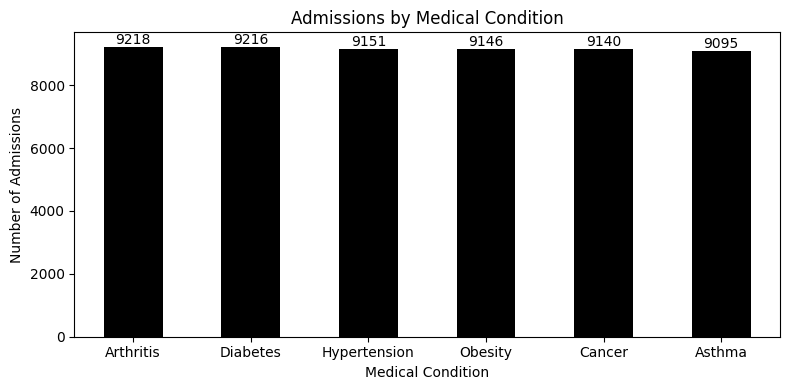

In [0]:
# Bar chart of the number of admissions for each medical condition.
ax = df_clean["Medical Condition"].value_counts().plot(kind="bar", color="black", figsize=(8, 4))
ax.bar_label(ax.containers[0], fmt="%d")
plt.title("Admissions by Medical Condition")
plt.xlabel("Medical Condition")
plt.ylabel("Number of Admissions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Observation**

The bars are almost equal in height. No condition dominates admissions.

### Patients by insurance provider

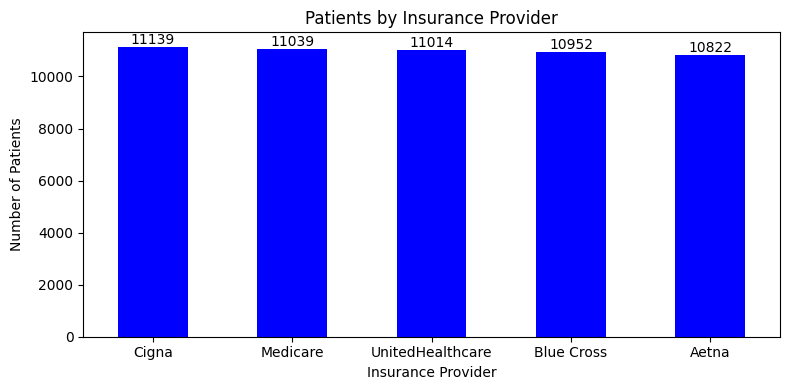

In [0]:
# Bar chart of the number of patients for each insurance provider.
ax = df_clean["Insurance Provider"].value_counts().plot(kind="bar", color="blue", figsize=(8, 4))
ax.bar_label(ax.containers[0], fmt="%d")
plt.title("Patients by Insurance Provider")
plt.xlabel("Insurance Provider")
plt.ylabel("Number of Patients")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Observation**

Cigna covers the most patients, but no provider is far ahead of the others.

### Age distribution

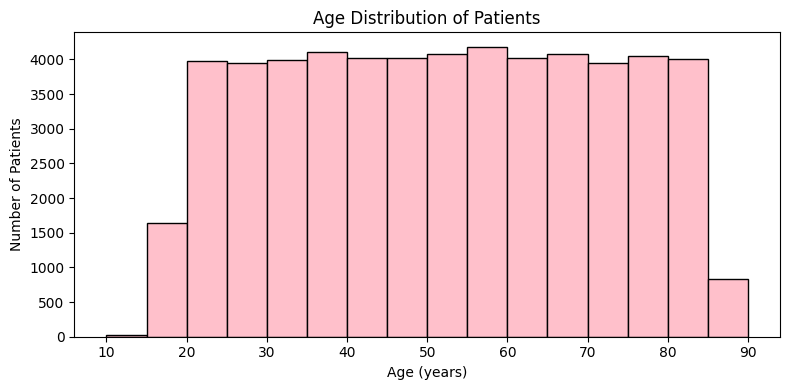

In [0]:
# Histogram of patient ages in 5-year bins.
plt.figure(figsize=(8, 4))
plt.hist(df_clean["Age"], bins=range(10, 95, 5), color="pink", edgecolor="black")
plt.title("Age Distribution of Patients")
plt.xlabel("Age (years)")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

**Observation**

The distribution is fairly flat from age 20 to 85. The first and last bars are smaller because the youngest patient is 13 and the oldest is 89.

### Admissions over time

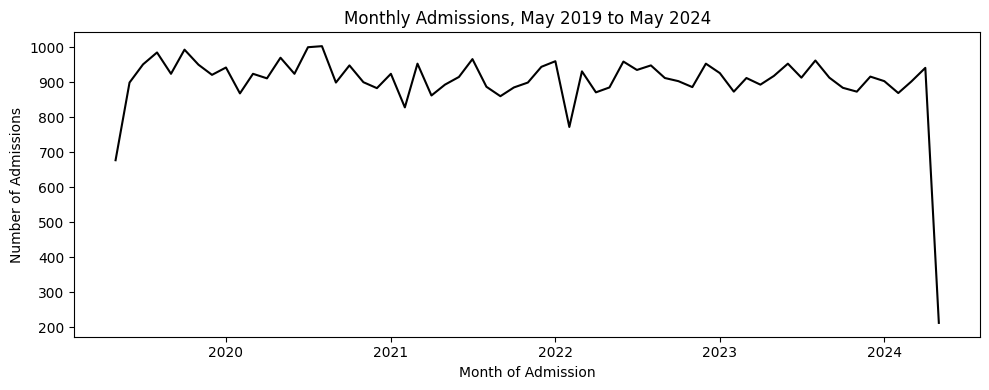

In [0]:
# Line chart of the number of admissions in each month.
monthly = df_clean.groupby(df_clean["Date of Admission"].dt.to_period("M")).size()

plt.figure(figsize=(10, 4))
plt.plot(monthly.index.to_timestamp(), monthly.values, color="black")
plt.title("Monthly Admissions, May 2019 to May 2024")
plt.xlabel("Month of Admission")
plt.ylabel("Number of Admissions")
plt.tight_layout()
plt.show()

**Observation**

Full months stay between 772 (February 2022) and 1,003 admissions. The low points at the start (677) and end (212) are not real drops. The first and last months are incomplete.

### Average billing amount by medical condition

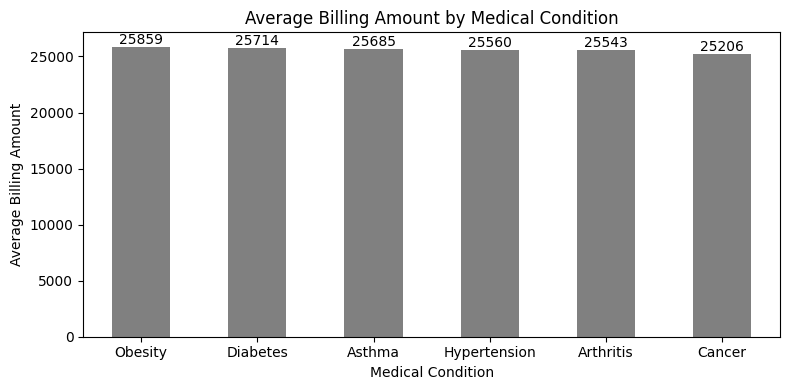

In [0]:
# Bar chart of the average billing amount for each medical condition.
avg_bill = df_clean.groupby("Medical Condition")["Billing Amount"].mean().sort_values(ascending=False)

ax = avg_bill.plot(kind="bar", color="gray", figsize=(8, 4))
ax.bar_label(ax.containers[0], fmt="%.0f")
plt.title("Average Billing Amount by Medical Condition")
plt.xlabel("Medical Condition")
plt.ylabel("Average Billing Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Observation**

Obesity has the highest average bill and Cancer the lowest. The axis starts at zero, so the bars look almost equal because the real difference is small (about 2.6%).

### Billing amount by admission type

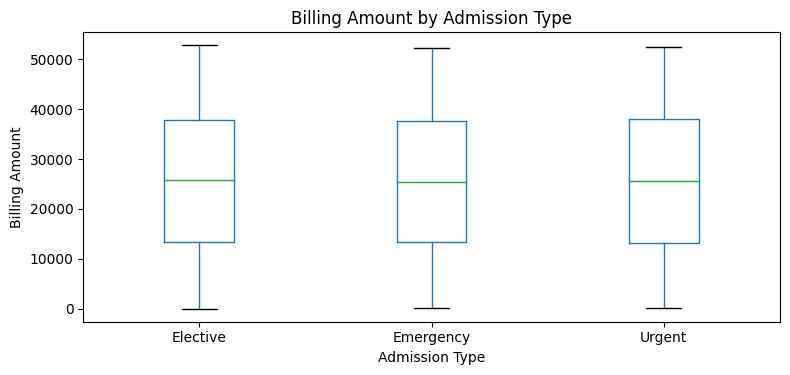

In [0]:
# Box plot of billing amounts for each admission type.
df_clean.boxplot(column="Billing Amount", by="Admission Type", figsize=(8, 4), grid=False)
plt.suptitle("")
plt.title("Billing Amount by Admission Type")
plt.xlabel("Admission Type")
plt.ylabel("Billing Amount")
plt.tight_layout()
plt.show()

**Observation**

The three boxes have almost the same median and range. The cost of an admission does not depend on admission type in this data.

### Test results by medical condition

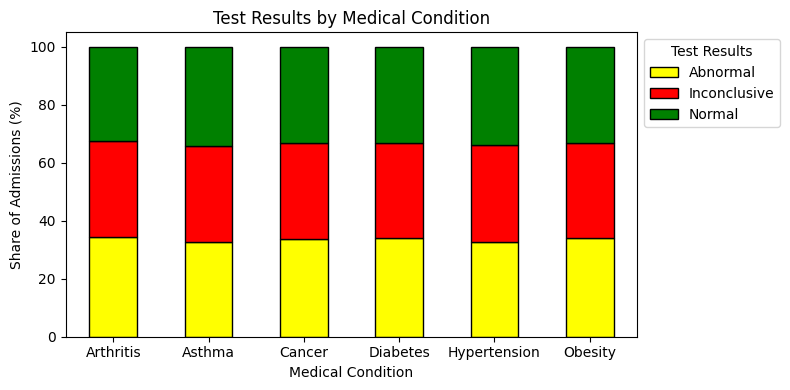

In [0]:
# Stacked bar chart of the share of each test result within each medical condition.
test_share = pd.crosstab(df_clean["Medical Condition"], df_clean["Test Results"], normalize="index") * 100

test_share.plot(kind="bar", stacked=True, figsize=(8, 4), color=["yellow", "red", "green"], edgecolor="black")
plt.title("Test Results by Medical Condition")
plt.xlabel("Medical Condition")
plt.ylabel("Share of Admissions (%)")
plt.xticks(rotation=0)
plt.legend(title="Test Results", loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

**Observation**

Each result makes up about a third of admissions for every condition.

## 8. Written Insights

1. Admissions are spread very evenly. The six conditions range only from 9,095 admissions (Asthma) to 9,218 (Arthritis), a gap of about 1.3%. The three admission types range from 18,102 to 18,473, and the five insurance providers from 10,822 to 11,139. Test results also split into roughly thirds for every condition.

2. Cost per admission barely changes with condition or admission type. The overall average bill is about 25,600. By condition it runs from 25,206 (Cancer) to 25,859 (Obesity), a gap of about 2.6%. By admission type it runs from 25,551 (Emergency) to 25,663 (Elective), a gap of about 0.4%.

3. Most stays are long and almost equal across conditions. The average stay is about 15.5 days, and by condition it only ranges from 15.43 days (Diabetes) to 15.68 days (Asthma). 42,080 of 54,966 admissions (about 77%) last 8 days or more.

4. Admissions were steady at about 11,000 a year from 2020 to 2023 (11,172, 10,816, 10,915 and 10,936). The lower totals for 2019 (7,300) and 2024 (3,827) are because the data only covers May 2019 to May 2024. August (4,785) and July (4,765) are the busiest months, and February (4,210) is the quietest.

5. Data quality limits what can be concluded. 534 rows were duplicates and 108 bills were negative. Names had random capitals and hospital names had stray commas. There are about 40,000 different hospital names and doctor names, and the busiest hospital name has only 44 admissions out of 54,966. This means the data cannot show which hospitals or doctors are really the busiest.

## 9. Executive Summary

This analysis looked at 55,500 hospital admission records from May 2019 to May 2024. The data was mostly in good shape. We removed 534 repeated records, tidied the patient names, and set aside 106 bills with negative amounts that cannot be right, leaving 54,966 admissions to study. The picture that came out is a very even one. The six medical conditions each account for about one sixth of admissions, and the three admission types and five insurance providers are split just as evenly. A typical admission costs about 25,600 and lasts about fifteen and a half days, and those figures hardly change from one condition to the next. Admissions held steady at around 11,000 a year between 2020 and 2023. Because the groups look so alike, the data does little to show where the hospital should focus its effort. It also looks simpler than real hospital records usually are, so any decision based on it should be made with care. The most useful next step is better record keeping, especially proper identifiers for hospitals and doctors.

## 10. Recommendations

1. Plan beds and staff around overall volume and length of stay, not around individual conditions (resource planning). Insight 3 shows that stays average about 15.5 days and are almost the same for every condition, and insight 4 shows about 11,000 admissions a year. Capacity should be planned on these steady figures, with extra cover in July and August, the busiest months.

2. Improve how records are collected (data collection). Insight 5 shows that duplicates, random capital letters, stray commas and about 40,000 different hospital names make the records hard to trust. Give every hospital, doctor and patient a unique ID, use drop-down lists instead of free text, and reject a record that exactly repeats an existing one.

3. Review the negative bills (cost review). 108 bills in the original data were below zero. The hospital should check whether these are refunds, corrections or typing errors, and record refunds in a separate field so that billing averages are not distorted.

4. Investigate further before acting on these results (follow-up investigation). Insights 1 and 2 show that conditions look almost identical on volume, cost and length of stay. Check whether extra detail, such as the type of treatment or how serious the case was, explains real differences. Also confirm with the data owner whether the dataset is complete or a simplified sample.